# Stream B: Acceptance Rule of the Backtest and Advised Strategies

**Master's Thesis Project:** Seasonality-Aware Drift Detection System  
**Stream B, week 3:** the acceptance rule (a recommended action is applied only if a backtest on the weeks before the decision confirms its gain), strategies that use it, an advisor with fixed rules and the LLM advisor, and the results per group of seasonal strength.

The results are computed by `python -m src.recommendations.run_backtest` (reference and gated strategies), `--advisors rules` (advised strategies) and `--strata` (seasonal strength), and read here from `data/processed/stream_b/`. The reference strategies give the same numbers as in `02_stream_b_baselines.ipynb`.

In [1]:
# Import required libraries
import sys
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Adds the parent directory (project root) to the Python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.recommendations.backtester import (ADVISED_STRATEGIES, DELTA, GATE_BLOCK_DAYS, STRATEGIES, VAL_WEEKS,
                                            backtest)
from src.recommendations.plots import plot_quality_cost

RESULTS = "../data/processed/stream_b"
runs = pd.read_csv(f"{RESULTS}/runs.csv")
summary = pd.read_csv(f"{RESULTS}/summary.csv")
strata = pd.read_csv(f"{RESULTS}/strata.csv")

SHOW = ["nothing", "scheduled", "scheduled_gate", "catalog_gate", "rules", "rules_gate", "llm", "llm_gate",
        "oracle_weekly"]
present = [s for s in SHOW if s in set(runs.strategy)]
KEY = ["source", "series", "scenario"]
print("Strategies in the results:", ", ".join(present))

Strategies in the results: nothing, scheduled, scheduled_gate, catalog_gate, rules, rules_gate, oracle_weekly


## 1. Acceptance Rule

At a decision point T the recommended action is replayed on the last weeks before T with a weekly rolling origin: at each origin its recipe is applied to the data before the origin and forecasts the following week. The reference is what the deployed model actually forecast in those weeks (day ahead, out of sample). Gain = MASE of the reference - MASE of the action, with a moving block bootstrap interval over days. The action is applied only if the lower bound of the 95% interval is above delta. Only data before T is used (a test changes the data after T and checks that the decision does not change).

In [2]:
print(f"check window: {VAL_WEEKS} weeks, bootstrap blocks: {GATE_BLOCK_DAYS} days, delta: {DELTA}")

check window: 2 weeks, bootstrap blocks: 3 days, delta: 0.0


## 2. Strategies

`scheduled_gate` and `catalog_gate` take a decision once a week, from the third week after deployment (the check needs two weeks of the strategy's own forecasts). The advised strategies ask an advisor for one action: `rules` follows fixed rules on the diagnostics, `llm` asks the LLM; the `_gate` versions apply the proposal only if the acceptance rule confirms it.

In [3]:
pd.DataFrame([(s.name, s.title_uk, s.cadence_days, s.policy, s.action or "", s.advisor or "",
               s.gate or s.policy == "gated") for s in STRATEGIES + ADVISED_STRATEGIES],
             columns=["strategy", "description", "every N days", "policy", "action", "advisor", "acceptance rule"])

,strategy,description,every N days,policy,action,advisor,acceptance rule
0,nothing,нічого не робити,NaN,fixed,,,False
1,always,завжди перенавчати (щодня),1.0,fixed,retrain_full,,False
2,scheduled,перенавчання за розкладом (щотижня),7.0,fixed,retrain_full,,False
3,scheduled_gate,"перенавчання щотижня, лише якщо бектест підтве...",7.0,gated,retrain_full,,True
4,catalog_gate,"щотижня найкраща дія каталогу з тих, що пройшл...",7.0,gated,,,True
5,oracle_weekly,оракул щотижня: найкраща дія каталогу за факто...,7.0,oracle,,,False
6,oracle,ідеальний оракул: найкраща дія каталогу за фак...,1.0,oracle,,,False
7,rules,"правила на діагностиці, без бектесту",7.0,advised,,rules,False
8,rules_gate,правила на діагностиці з бектестом,7.0,advised,,rules,True
9,llm,LLM без бектесту,7.0,advised,,llm,False


## 3. Results

Mean over series per source, scenario and strategy. `retrains` counts deployed retrainings; `accept_rate` is the share of proposed changes that were applied (for the gated strategies: that passed the check); `check_fits` counts the model fits the checks needed (the computational cost of the backtest).

In [4]:
cols = ["source", "scenario", "strategy", "series", "mase_post", "regret", "retrains", "gain_vs_nothing",
        "share_gain_significant", "accept_rate", "check_fits"]
summary[summary.strategy.isin(present)][cols].round(3)

,source,scenario,strategy,series,mase_post,regret,retrains,gain_vs_nothing,share_gain_significant,accept_rate,check_fits
1,entsoe,lockdown_2020,nothing,8,0.787,0.301,0.000,NaN,NaN,NaN,NaN
3,entsoe,lockdown_2020,scheduled,8,0.696,0.209,24.000,0.092,0.625,NaN,NaN
4,entsoe,lockdown_2020,scheduled_gate,8,0.717,0.231,3.375,0.070,0.625,0.147,46.000
5,entsoe,lockdown_2020,catalog_gate,8,0.738,0.252,6.000,0.049,0.250,0.332,230.000
6,entsoe,lockdown_2020,oracle_weekly,8,0.607,0.121,17.500,0.180,1.000,NaN,NaN
8,entsoe,lockdown_2020,rules,8,0.974,0.488,1.000,-0.187,0.000,1.000,0.000
9,entsoe,lockdown_2020,rules_gate,8,0.780,0.293,0.000,0.008,0.000,0.226,3.500
11,seismic,lockdown_2020,nothing,15,1.449,0.693,0.000,NaN,NaN,NaN,NaN
13,seismic,lockdown_2020,scheduled,15,0.998,0.241,11.000,0.452,0.800,NaN,NaN
14,seismic,lockdown_2020,scheduled_gate,15,1.092,0.335,2.933,0.357,0.467,0.293,20.000


Reference strategies and the strategies with the acceptance rule:

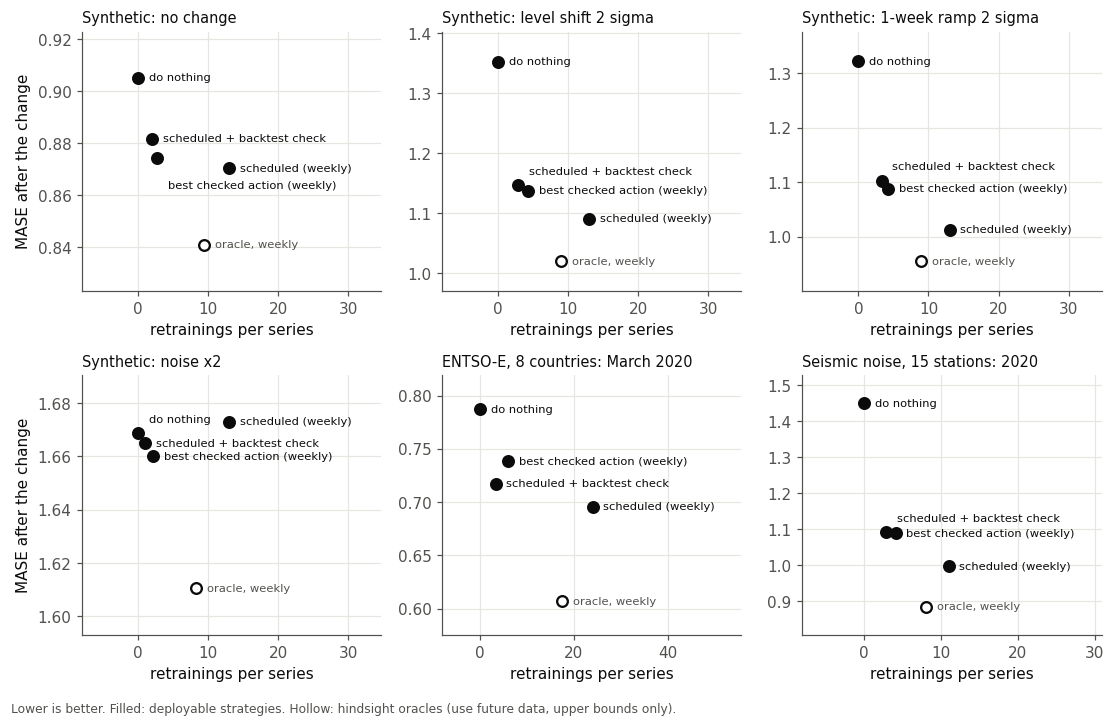

In [5]:
fig = plot_quality_cost(summary[summary.strategy.isin(["nothing", "scheduled", "scheduled_gate", "catalog_gate",
                                                       "oracle_weekly"])])
plt.show()

Advised strategies, without and with the acceptance rule:

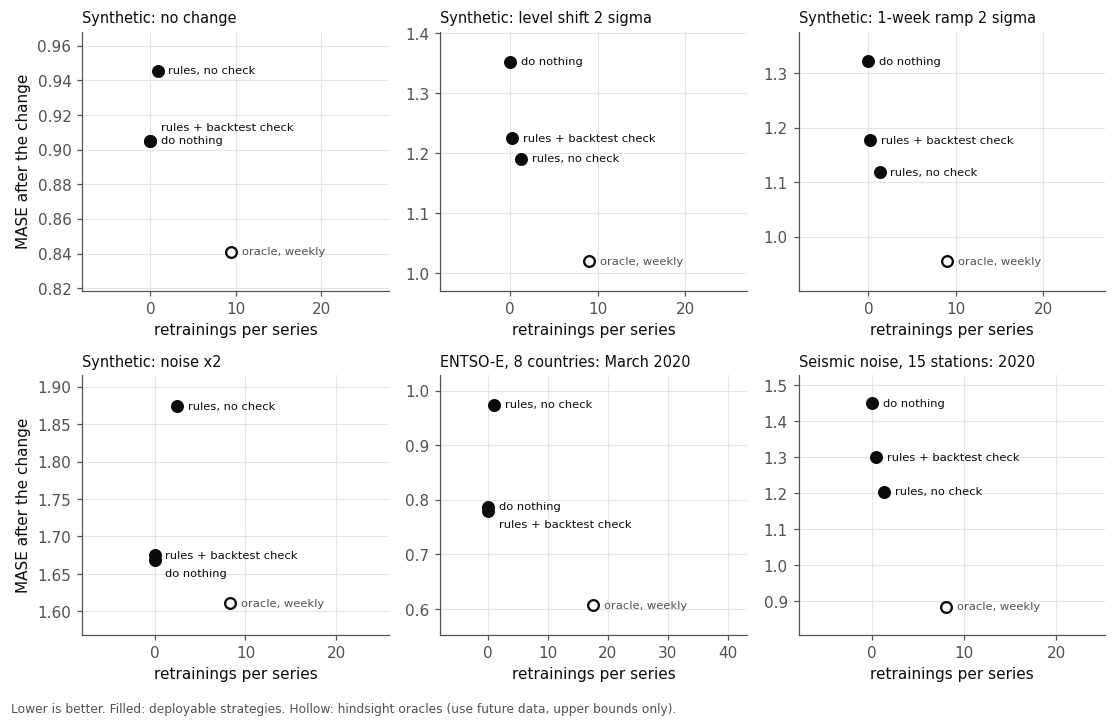

In [6]:
fig = plot_quality_cost(summary[summary.strategy.isin(["nothing", "rules", "rules_gate", "llm", "llm_gate",
                                                       "oracle_weekly"])])
plt.show()

## 4. What the Check Changes

Each strategy against its version with the acceptance rule: retrainings saved, MASE after the change, and the share of series where the checked version is not worse.

In [7]:
mase = runs.pivot_table(index=KEY, columns="strategy", values="mase_post")
retr = runs.pivot_table(index=KEY, columns="strategy", values="retrains")
rows = []
for a, b in [("scheduled", "scheduled_gate"), ("rules", "rules_gate"), ("llm", "llm_gate")]:
    if a not in mase or b not in mase:
        continue
    for (src, sc), g in mase.groupby(level=["source", "scenario"]):
        r = retr.loc[g.index]
        rows.append(dict(source=src, scenario=sc, pair=f"{a} -> {b}", retrains=r[a].mean(), retrains_checked=r[b].mean(),
                         saved=1 - r[b].sum() / r[a].sum() if r[a].sum() else np.nan,
                         mase_post=g[a].mean(), mase_post_checked=g[b].mean(),
                         not_worse=(g[b] <= g[a] + 1e-9).mean()))
pd.DataFrame(rows).round(3)

,source,scenario,pair,retrains,retrains_checked,saved,mase_post,mase_post_checked,not_worse
0,entsoe,lockdown_2020,scheduled -> scheduled_gate,24.000,3.375,0.859,0.696,0.717,0.250
1,seismic,lockdown_2020,scheduled -> scheduled_gate,11.000,2.933,0.733,0.998,1.092,0.000
2,synthetic,level_shift,scheduled -> scheduled_gate,13.000,2.867,0.779,1.091,1.147,0.150
3,synthetic,none,scheduled -> scheduled_gate,13.000,2.017,0.845,0.870,0.882,0.050
4,synthetic,trend_ramp,scheduled -> scheduled_gate,13.000,3.333,0.744,1.013,1.103,0.000
5,synthetic,variance,scheduled -> scheduled_gate,13.000,1.000,0.923,1.673,1.665,0.533
6,entsoe,lockdown_2020,rules -> rules_gate,1.000,0.000,1.000,0.974,0.780,0.875
7,seismic,lockdown_2020,rules -> rules_gate,1.267,0.467,0.632,1.204,1.300,0.400
8,synthetic,level_shift,rules -> rules_gate,1.250,0.233,0.813,1.191,1.225,0.233
9,synthetic,none,rules -> rules_gate,0.833,0.000,1.000,0.946,0.905,1.000


## 5. Results per Group of Seasonal Strength

Seasonal strength F = max(0, 1 - Var(R) / Var(S + R)) from an MSTL decomposition (periods 24 and 168) of the last 8 weeks before deployment (Wang, Smith and Hyndman 2006; FPP3, 4.3). The series were chosen for their seasonality and the daily pattern is strong in almost all of them, so the groups are the thirds of the strength over all series (low, medium, high); the real series fall in the lower two thirds, so the groups are also compared within the synthetic series. Series with a change only (synthetic `none` is left out); mean gain over `nothing` after the change, in MASE units.

In [8]:
print(strata.groupby(["source", "group"]).size().unstack(fill_value=0)[["low", "medium", "high"]])
print(strata.groupby("group").strength.agg(["min", "max"]).reindex(["low", "medium", "high"]).round(3))
r = runs.merge(strata[KEY + ["group", "strength"]], on=KEY)
r = r[(r.scenario != "none") & r.strategy.isin(present[1:])]


def by_group(d):
    t = d.pivot_table(index="group", columns="strategy", values="gain_vs_nothing", aggfunc="mean")
    t = t.reindex(["low", "medium", "high"])[[s for s in present[1:] if s in t]]
    t.insert(0, "series", d.drop_duplicates(KEY).groupby("group").size())
    return t.round(3)


display(by_group(r))
display(by_group(r[r.source == "synthetic"]))

group      low  medium  high
source                      
entsoe       5       3     0
seismic     11       4     0
synthetic   72      80    88
          min    max
group               
low     0.578  0.909
medium  0.911  0.968
high    0.968  0.989


strategy,series,scheduled,scheduled_gate,catalog_gate,rules,rules_gate,oracle_weekly
group,,,,,,,
low,70,0.290,0.228,0.234,0.162,0.165,0.360
medium,67,0.128,0.091,0.090,0.001,0.026,0.192
high,66,0.190,0.145,0.164,0.006,0.077,0.261


strategy,series,scheduled,scheduled_gate,catalog_gate,rules,rules_gate,oracle_weekly
group,,,,,,,
low,54,0.248,0.193,0.202,0.150,0.163,0.305
medium,60,0.134,0.095,0.096,0.019,0.037,0.195
high,66,0.190,0.145,0.164,0.006,0.077,0.261


## 6. What the LLM Advisor Sees

The diagnostics and the prompt at the first weekly review after the lockdown for the Milan seismic station, with the model that was never changed. The answer schema allows one catalog action and a short reason; the rules advisor answers on the same numbers.

In [9]:
from src.recommendations.data_sources import seismic_series
from src.recommendations.forecast import DAY, WEEK, mase_scale
from src.recommendations.llm_client import RuleAdvisor, diagnostics, render_prompt

(s,) = seismic_series("../data/raw/seismic_noise", stations=("IV.MILN",))
nothing = backtest(s["y"], s["F"], s["t_deploy"], STRATEGIES[0], s["base_features"])
T = s["t_deploy"] + ((s["t_change"] - s["t_deploy"]) // WEEK + 1) * WEEK
ctx = diagnostics(s["y"], nothing["pred"], T, s["t_deploy"], mase_scale(s["y"][:s["t_deploy"]]), s["t_deploy"])
system, user = render_prompt(ctx)
print(system, user, sep="\n\n")
print("\nrules advisor:", RuleAdvisor().recommend(ctx))

You maintain an hourly forecasting model in production. Every day at 00:00 it forecasts the next
24 hours (gradient boosting on lagged values and calendar features). At a review point you get diagnostics
computed from the data up to now and choose exactly one action from the catalog. Every retraining has a
cost, so choose "keep" when the evidence for a change is weak.

Catalog:
- keep: do nothing (no retraining)
- retrain_full: retrain on all history (retrains the model)
- retrain_8w: retrain on the last 8 weeks (retrains the model)
- retrain_2w: shorten the training window to 2 weeks (retrains the model)
- reweight_1w: reweight recent data (weight half-life 1 week) (retrains the model)
- add_profile: add a seasonal feature: 4-week hour-of-week profile (retrains the model)
- recalibrate_level: recalibrate the forecast level on the last week (no retraining)

Answer with the action name and a short reason.

Diagnostics (errors are MASE: 1.0 = error of the weekly seasonal naive forecast o

## 7. Consistency Checks

In [10]:
ok = runs[runs.strategy.isin(["scheduled_gate", "catalog_gate", "rules", "rules_gate", "llm", "llm_gate"])]
print("accepted <= proposed <= decisions:", bool(((ok.accepted <= ok.proposed.fillna(ok.decisions))
      & (ok.proposed.fillna(ok.decisions) <= ok.decisions)).all()), f"({len(ok)} runs)")
print(f"scheduled_gate retrains <= scheduled on {(retr.scheduled_gate <= retr.scheduled).sum()} of {len(retr)} series")

accepted <= proposed <= decisions: True (1052 runs)
scheduled_gate retrains <= scheduled on 263 of 263 series


## 8. Findings

All numbers are means over the 263 series (tables above).

- **The check saves most retrainings, at a cost in error.** `scheduled_gate` retrains 73% to 92% less often than `scheduled` in every source and scenario. The error after the change is higher: 0.717 against 0.696 on ENTSO-E, 1.092 against 0.998 on seismic noise, 1.147 against 1.091 after a synthetic level shift. The check needs two weeks of evidence after a change, so it reacts later than a weekly retraining.
- **Where retraining hurts, the check stops it.** With doubled noise, weekly retraining is worse than doing nothing on half of the synthetic series; the checked version retrains 92% less often and keeps the error at the level of doing nothing (1.665 against 1.669).
- **The check protects against bad advice.** The rules advisor applied without the check is worse than doing nothing on ENTSO-E (0.974 against 0.787) and with doubled noise (1.873 against 1.669). With the check the error returns to the level of doing nothing (0.780 and 1.675), and the share of series where the advised strategy is worse than doing nothing falls from 75% to 25% on ENTSO-E and from 100% to 12% with doubled noise (after a synthetic ramp it rises from 10% to 18%: the check is not a guarantee). Where the rules help (seismic noise, synthetic shift and ramp), the check also removes part of their gain (1.300 against 1.204 on seismic noise): it applies only what two weeks of data confirm. This is the comparison that RQ3 makes for the LLM: a recommendation with the backtest against the same recommendation without it.
- **Checking one proposal is cheap, checking the whole catalog is not.** `catalog_gate` needs 122 model fits per series for its checks, `scheduled_gate` 24, `rules_gate` 6, with a similar error for the first two. An advisor that proposes one action to check is what makes the backtest affordable.
- **There is room for a better advisor.** The weekly oracle stays well ahead of every deployable strategy (for example 0.885 against 1.089 for `catalog_gate` on seismic noise).
- **Seasonal strength.** The order of the strategies is nearly the same in every third of seasonal strength: weekly retraining first, the two checked strategies close to each other, then the rules advisor. The gains of all strategies are largest in the lower third and smallest in the middle third, also within the synthetic series alone; the rules advisor gains almost nothing in the middle and upper thirds.
- **Settings.** The check window (2 weeks), the 95% interval and delta = 0 follow the application and were not tuned. A less strict interval would apply more actions; if it is tuned, it must be on the validation series, not on these.

## 9. Next Steps

- LLM pilot: `--advisors llm` on the real series (ENTSO-E and seismic noise), the cheap model first, then the model of the application; three repeats of every request to measure the spread of the answers.
- Decisions tied to detector alarms instead of weekly reviews: `BaselineDetectorWrapper.run` from Stream A returns the alarm indices; this needs thresholds calibrated on the control series, otherwise the detectors raise alarms at almost every check.
- Ablation of the diagnostics: the LLM without the numbers (`render_prompt(..., with_diagnostics=False)`).